<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Procesamiento de Lenguaje Natural · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Subtarea 1: Detección de Polarización con un Metamodelo por Idioma (SemEval-2026 Task 9)</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Pérez Martínez Ángel Noel, Zamora Antiga Ángel Javier</div><img src="https://raw.githubusercontent.com/makore-0612/vibe-rhythming/refs/heads/main/assets/logoinst.png" width="200"/></div>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Objetivo</span></div>

El objetivo de este notebook es clasificar cada texto como polarizado o no polarizado (subtarea 1) con un **metamodelo por idioma**. Se trata de una sola clase que recibe textos de cualquiera de los 22 idiomas y envía cada uno, de forma automática, al modelo entrenado para su idioma.

Se comparan cuatro configuraciones, para separar el efecto de entrenar por idioma del efecto del ensamble.

| | Regresión logística | Voto suave (regresión logística + Random Forest) |
|:--|:--|:--|
| **Por idioma** | 22 modelos, uno por idioma | 22 ensambles, uno por idioma |
| **Global** | 1 modelo para todos los idiomas | 1 ensamble para todos los idiomas |

La métrica es el **F1 macro**, que promedia el F1 de ambas clases y no premia predecir siempre la clase mayoritaria, algo importante en idiomas como el jemer, donde el 91% de los textos son polarizados.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Preparación de entorno</span></div>

In [1]:
# Manejo de datos
import os
import time
import joblib
import warnings
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.stats import wilcoxon
from joblib import Parallel, delayed

# Modelos
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.utils.validation import check_is_fitted
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibilidad
random_state = 42

# Rutas
ruta_datos = 'data'
ruta_procesado = os.path.join(ruta_datos, 'procesado')
ruta_tfidf = os.path.join(ruta_datos, 'tfidf')
ruta_predicciones = os.path.join(ruta_datos, 'predicciones')

warnings.filterwarnings('ignore', category = FutureWarning)

In [2]:
train = pd.read_csv(os.path.join(ruta_procesado, 'train.csv'))
test = pd.read_csv(os.path.join(ruta_procesado, 'test.csv')).drop(columns = ['canary'])
idiomas = sorted(train['idioma'].unique())

vectorizadores = joblib.load(os.path.join(ruta_tfidf, 'vectorizadores_idioma.joblib'))
X_train_global = sparse.load_npz(os.path.join(ruta_tfidf, 'X_train_global.npz')).tocsr()
X_test_global = sparse.load_npz(os.path.join(ruta_tfidf, 'X_test_global.npz')).tocsr()

y_train = train['polarization'].values
y_test = test['polarization'].values

print(f'Tamaño de train: {train.shape}, matriz global: {X_train_global.shape}')
print(f'Tamaño de test: {test.shape}, matriz global: {X_test_global.shape}')
print(f'Vectorizadores por idioma: {len(vectorizadores)}')

Tamaño de train: (73454, 15), matriz global: (73454, 762279)
Tamaño de test: (33288, 15), matriz global: (33288, 762279)
Vectorizadores por idioma: 22


Se cargan los resultados de la etapa de preprocesamiento, es decir, los textos limpios de `data/procesado/` y los vectorizadores TF-IDF de `data/tfidf/`, que se ajustaron solo con `train`. Para el modelo global se usan directamente las matrices globales guardadas.

Todos los hiperparámetros y umbrales se eligen con validación cruzada dentro de `train`, y `test` se usa una sola vez, al final, para comparar las cuatro configuraciones.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Selección de los modelos del ensamble</span></div>

In [3]:
modelos_base = {
    'LR': lambda: LogisticRegression(C = 10, max_iter = 3000, class_weight = 'balanced'),
    'SVC': lambda: CalibratedClassifierCV(LinearSVC(C = 0.5, class_weight = 'balanced'), cv = 3),
    'CNB': lambda: ComplementNB(alpha = 0.3),
    'RF': lambda: RandomForestClassifier(n_estimators = 200, class_weight = 'balanced', n_jobs = 1, random_state = random_state)
}
combinaciones = [('LR', 'SVC', 'CNB'), ('LR', 'SVC', 'CNB', 'RF'), ('LR', 'SVC', 'RF'), ('LR', 'RF')]
umbrales = np.round(np.arange(0.05, 0.951, 0.01), 2)

def mejor_umbral(y, proba):
    """
    Función que elige el umbral de decisión que maximiza el F1 macro

    inputs:
    --------
        y (numpy.ndarray): Etiquetas verdaderas
        proba (numpy.ndarray): Probabilidades estimadas de la clase positiva

    outputs:
    --------
        float: Umbral con mayor F1 macro
    """
    f1 = [f1_score(y, (proba >= u).astype(int), average = 'macro') for u in umbrales]
    return umbrales[np.argmax(f1)]

def comparar_idioma(idioma):
    """
    Función que evalúa con validación cruzada los modelos base y sus combinaciones en un idioma

    inputs:
    --------
        idioma (str): Código del idioma

    outputs:
    --------
        list: Tuplas (idioma, partición, modelo, F1 macro)
    """
    warnings.filterwarnings('ignore')
    X = sparse.load_npz(os.path.join(ruta_tfidf, 'idioma', f'X_train_{idioma}.npz')).tocsr()
    y = train.loc[train['idioma'] == idioma, 'polarization'].values
    resultados = []
    particiones = StratifiedKFold(5, shuffle = True, random_state = random_state)
    for k, (entr, val) in enumerate(particiones.split(X, y)):
        p_val, p_int = {}, {}
        internas = StratifiedKFold(3, shuffle = True, random_state = random_state)
        for nombre, modelo in modelos_base.items():
            p_val[nombre] = modelo().fit(X[entr], y[entr]).predict_proba(X[val])[:, 1]
            p_int[nombre] = cross_val_predict(modelo(), X[entr], y[entr], cv = internas, method = 'predict_proba')[:, 1]

        pred = {nombre: (p_val[nombre] >= 0.5).astype(int) for nombre in modelos_base}
        pred['LR + umbral'] = (p_val['LR'] >= mejor_umbral(y[entr], p_int['LR'])).astype(int)
        for combo in combinaciones:
            nombre = '+'.join(combo)
            pv = np.mean([p_val[c] for c in combo], axis = 0)
            pi = np.mean([p_int[c] for c in combo], axis = 0)
            pred[f'Voto {nombre}'] = (pv >= 0.5).astype(int)
            pred[f'Voto {nombre} + umbral'] = (pv >= mejor_umbral(y[entr], pi)).astype(int)
            meta = LogisticRegression(class_weight = 'balanced').fit(np.column_stack([p_int[c] for c in combo]), y[entr])
            pred[f'Stacking {nombre}'] = meta.predict(np.column_stack([p_val[c] for c in combo]))

        resultados += [(idioma, k, nombre, f1_score(y[val], p, average = 'macro')) for nombre, p in pred.items()]
    return resultados

inicio = time.perf_counter()
resultados = Parallel(n_jobs = -1)(delayed(comparar_idioma)(idioma) for idioma in idiomas)
seleccion = pd.DataFrame([r for res in resultados for r in res], columns = ['idioma', 'particion', 'modelo', 'f1'])
print(f'Tiempo: {(time.perf_counter() - inicio) / 60:.1f} min')

# F1 macro medio de cada modelo en cada idioma
f1_idioma = seleccion.groupby(['modelo', 'idioma'])['f1'].mean().unstack()
base = f1_idioma.loc['LR']
resumen_seleccion = pd.DataFrame({
    'F1 macro medio': f1_idioma.mean(axis = 1),
    'diferencia con LR': f1_idioma.mean(axis = 1) - base.mean(),
    'idiomas donde supera a LR': f1_idioma.gt(base, axis = 1).sum(axis = 1),
    'p (Wilcoxon)': [wilcoxon(f1_idioma.loc[m], base).pvalue if m != 'LR' else np.nan for m in f1_idioma.index]
}).sort_values('F1 macro medio', ascending = False)
display(resumen_seleccion.round(4))
print(f"Desviación estándar media de LR entre particiones: {seleccion[seleccion['modelo'] == 'LR'].groupby('idioma')['f1'].std().mean():.4f}")

Tiempo: 12.5 min


,F1 macro medio,diferencia con LR,idiomas donde supera a LR,p (Wilcoxon)
modelo,,,,
Voto LR+SVC+CNB+RF + umbral,0.7471,0.0090,19,0.0000
Voto LR+RF + umbral,0.7469,0.0088,22,0.0000
Voto LR+SVC+RF + umbral,0.7465,0.0084,22,0.0000
Voto LR+SVC+CNB + umbral,0.7426,0.0045,16,0.0115
Stacking LR+SVC+CNB+RF,0.7423,0.0042,15,0.0738
Stacking LR+SVC+RF,0.7402,0.0021,16,0.0854
Voto LR+RF,0.7396,0.0015,18,0.0115
Stacking LR+RF,0.7391,0.0010,15,0.2221
LR,0.7381,0.0000,0,NaN


Desviación estándar media de LR entre particiones: 0.0179


En esta celda se decide qué modelos combinar antes de construir el metamodelo. Se comparan cuatro modelos base y varias formas de combinarlos, con validación cruzada de 5 particiones en cada idioma.

* **Modelos base.** Regresión logística, LinearSVC calibrado (para obtener probabilidades), Naive Bayes complementario y Random Forest.
* **Voto suave.** Promedio de las probabilidades de los modelos, con umbral 0.5 o con un umbral ajustado.
* **Stacking.** Una regresión logística que aprende a combinar las probabilidades de los modelos base.

El umbral del voto y los datos del stacking se obtienen con una validación cruzada interna de 3 particiones dentro de cada partición de entrenamiento, así que la partición de validación nunca se usa para ajustar nada. Los hiperparámetros están fijos para que la comparación sea entre modelos y no entre búsquedas de hiperparámetros.

Se usan las matrices TF-IDF por idioma de la etapa anterior, cuyo vocabulario e IDF se calcularon con todo `train`. Esto introduce una fuga mínima y no supervisada, puesto que no usa etiquetas, que afecta por igual a todos los modelos y no cambia la comparación. La celda tarda alrededor de 10 minutos.

* **El mejor ensamble es el más simple.** El voto suave de regresión logística y Random Forest con umbral ajustado empata con el voto de los cuatro modelos (0.7469 contra 0.7471), pero supera a la regresión logística en los 22 idiomas en lugar de 19 y usa la mitad de modelos. La mejora es pequeña (menos de un punto de F1 macro, por debajo de la variación entre particiones), pero muy consistente, y la prueba de Wilcoxon pareada por idioma la confirma.
* **El Random Forest por sí solo es el peor modelo, pero es el que más aporta al ensamble.** Sobre matrices TF-IDF dispersas un modelo lineal, que suma evidencia de miles de n-gramas a la vez, funciona mejor que los árboles, que deciden con unos pocos. Justo por eso el bosque se equivoca en textos distintos que la regresión logística, y esa diversidad es lo que aprovecha el voto. LinearSVC y Naive Bayes son modelos lineales sobre las mismas variables y cometen casi los mismos errores que la regresión logística, así que no aportan.
* **Sin ajustar el umbral, el voto empeora.** Las probabilidades del Random Forest se concentran cerca de la proporción de clases, lo que desplaza la escala del promedio, y en idiomas desbalanceados como el jemer el umbral de 0.5 queda muy mal ubicado. El umbral por sí solo no mejora a la regresión logística, entonces la ganancia del voto viene de la combinación y no del umbral.
* **El stacking es inestable** con pocos miles de textos por idioma, ya que mejora en promedio pero empeora claramente en algunos idiomas.

Como se probaron 16 configuraciones y se eligió la mejor, es probable que la mejora real sea algo menor que la observada aquí. Por eso la comparación final se hace en `test`, que no participó en esta selección.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metamodelo</span></div>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Voto suave con umbral ajustado</span></div>

In [4]:
class VotoSuave(BaseEstimator, ClassifierMixin):
    """
    Clasificador binario que promedia las probabilidades de varios clasificadores y decide con un umbral ajustado

    inputs:
    --------
        estimadores (list): Clasificadores de scikit-learn con método predict_proba
        ajustar_umbral (bool): Si es True, el umbral se elige por validación cruzada; si es False, se usa 0.5
        cv (int): Cantidad de particiones para estimar el umbral
        random_state (int): Semilla de las particiones

    outputs:
    --------
        Atributos tras el ajuste: estimadores_ (modelos entrenados), umbral_ (umbral de decisión), classes_
    """
    def __init__(self, estimadores, ajustar_umbral = True, cv = 3, random_state = 42):
        self.estimadores = estimadores
        self.ajustar_umbral = ajustar_umbral
        self.cv = cv
        self.random_state = random_state

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        if len(self.classes_) != 2:
            raise ValueError('VotoSuave solo admite clasificación binaria')

        if self.ajustar_umbral:
            particiones = StratifiedKFold(self.cv, shuffle = True, random_state = self.random_state)
            proba = np.mean([cross_val_predict(clone(e), X, y, cv = particiones, method = 'predict_proba')[:, 1]
                             for e in self.estimadores], axis = 0)
            self.umbral_ = mejor_umbral(y, proba)
        else:
            self.umbral_ = 0.5

        self.estimadores_ = [clone(e).fit(X, y) for e in self.estimadores]
        return self

    def predict_proba(self, X):
        check_is_fitted(self)
        return np.mean([e.predict_proba(X) for e in self.estimadores_], axis = 0)

    def predict(self, X):
        return self.classes_[(self.predict_proba(X)[:, 1] >= self.umbral_).astype(int)]

`VotoSuave` promedia las probabilidades de varios clasificadores. Si `ajustar_umbral = True`, antes de entrenar los modelos con todos los datos obtiene probabilidades fuera de muestra con validación cruzada y elige el umbral que maximiza el F1 macro. De esta forma el umbral nunca se elige con predicciones sobre textos que el modelo ya vio.

La clase hereda de `BaseEstimator` y `ClassifierMixin`, entonces se comporta como cualquier clasificador de `scikit-learn` y se puede clonar, anidar o evaluar con sus funciones.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Clasificador por idioma</span></div>

In [5]:
def ajustar_idioma(estimador, vectorizador, textos, y):
    """
    Función que vectoriza los textos de un idioma y entrena su clasificador

    inputs:
    --------
        estimador: Clasificador de scikit-learn sin entrenar
        vectorizador (TfidfVectorizer): Vectorizador ya ajustado del idioma
        textos (numpy.ndarray): Textos limpios del idioma
        y (numpy.ndarray): Etiquetas

    outputs:
    --------
        Clasificador entrenado
    """
    warnings.filterwarnings('ignore', category = FutureWarning)
    return estimador.fit(vectorizador.transform(textos), y)


class ClasificadorPorIdioma(BaseEstimator, ClassifierMixin):
    """
    Metamodelo que entrena un clasificador por idioma y envía cada texto al modelo de su idioma

    inputs:
    --------
        vectorizadores (dict): Vectorizadores ya ajustados, con el código de idioma como llave
        estimador: Clasificador de scikit-learn que se copia y entrena para cada idioma
        n_jobs (int): Cantidad de idiomas que se entrenan en paralelo (-1 usa todos los núcleos)

    outputs:
    --------
        Atributos tras el ajuste: modelos_ (dict con un clasificador entrenado por idioma), idiomas_, classes_
    """
    def __init__(self, vectorizadores, estimador, n_jobs = None):
        self.vectorizadores = vectorizadores
        self.estimador = estimador
        self.n_jobs = n_jobs

    @staticmethod
    def _separar(X):
        return X['texto'].to_numpy(), X['idioma'].to_numpy()

    @staticmethod
    def _validar_idiomas(idiomas, disponibles):
        faltantes = set(idiomas) - set(disponibles)
        if faltantes:
            raise ValueError(f'No hay modelo para los idiomas: {sorted(faltantes)}')

    def fit(self, X, y):
        textos, idiomas = self._separar(X)
        y = np.asarray(y)
        self._validar_idiomas(idiomas, self.vectorizadores)
        self.idiomas_ = sorted(set(idiomas))
        self.classes_ = np.unique(y)

        modelos = Parallel(n_jobs = self.n_jobs)(
            delayed(ajustar_idioma)(clone(self.estimador), self.vectorizadores[i], textos[idiomas == i], y[idiomas == i])
            for i in self.idiomas_)
        self.modelos_ = dict(zip(self.idiomas_, modelos))
        return self

    def _aplicar(self, metodo, X):
        check_is_fitted(self)
        textos, idiomas = self._separar(X)
        self._validar_idiomas(idiomas, self.modelos_)
        salida = None
        for i in np.unique(idiomas):
            filas = idiomas == i
            resultado = getattr(self.modelos_[i], metodo)(self.vectorizadores[i].transform(textos[filas]))
            if salida is None:
                salida = np.empty((len(textos),) + resultado.shape[1:], dtype = resultado.dtype)
            salida[filas] = resultado
        return salida

    def predict_proba(self, X):
        return self._aplicar('predict_proba', X)

    def predict(self, X):
        return self._aplicar('predict', X)

`ClasificadorPorIdioma` es el metamodelo. Recibe un `DataFrame` con las columnas `texto` e `idioma` y trabaja en dos momentos.

* **Al entrenar**, agrupa los textos por idioma, los transforma con el vectorizador de ese idioma y entrena una copia independiente del estimador base para cada uno. Los idiomas se entrenan en paralelo con la función `ajustar_idioma`.
* **Al predecir**, envía cada texto al vectorizador y al modelo de su idioma y devuelve las predicciones **en el orden original** de las filas, aunque los idiomas vengan mezclados.

El estimador base puede ser cualquier clasificador de `scikit-learn` (una regresión logística, un `VotoSuave`, etc.), así que la misma clase sirve para cualquier modelo y en la subtarea 2 se puede usar con un clasificador multietiqueta.

In [6]:
muestra = train[train['idioma'].isin(['eng', 'spa', 'zho'])]
prueba = ClasificadorPorIdioma(vectorizadores, LogisticRegression(max_iter = 1000)).fit(muestra, muestra['polarization'])

mezcla = test[test['idioma'].isin(['eng', 'spa', 'zho'])].sample(frac = 1, random_state = random_state)
a_mano = np.array([prueba.modelos_[i].predict(vectorizadores[i].transform([t]))[0]
                   for t, i in zip(mezcla['texto'], mezcla['idioma'])])
print(f"Primeros idiomas de la muestra: {list(mezcla['idioma'].head(8))}")
print(f'Predicciones idénticas a las hechas a mano: {np.array_equal(prueba.predict(mezcla), a_mano)}')

Primeros idiomas de la muestra: ['spa', 'zho', 'spa', 'spa', 'zho', 'spa', 'spa', 'eng']
Predicciones idénticas a las hechas a mano: True


Antes de usar el metamodelo se comprueba que el enrutamiento conserva el orden. Se entrena con una muestra de tres idiomas (inglés, español y chino), se desordenan los textos de prueba y se comparan las predicciones del metamodelo con las que se obtienen al llamar a mano al modelo de cada idioma. La salida muestra que los idiomas quedaron mezclados y que las predicciones coinciden por completo.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Entrenamiento</span></div>

In [7]:
def regresion_logistica(n_jobs = None):
    """
    Función que construye la regresión logística con búsqueda de C por validación cruzada

    inputs:
    --------
        n_jobs (int): Núcleos para la búsqueda de C

    outputs:
    --------
        LogisticRegressionCV: Clasificador sin entrenar
    """
    return LogisticRegressionCV(Cs = [0.3, 1, 3, 10, 30], cv = StratifiedKFold(3, shuffle = True, random_state = random_state),
                                scoring = 'f1_macro', class_weight = 'balanced', max_iter = 3000, n_jobs = n_jobs)

def bosque(n_arboles, n_jobs = None):
    """
    Función que construye el Random Forest

    inputs:
    --------
        n_arboles (int): Cantidad de árboles
        n_jobs (int): Núcleos para entrenar los árboles

    outputs:
    --------
        RandomForestClassifier: Clasificador sin entrenar
    """
    return RandomForestClassifier(n_estimators = n_arboles, class_weight = 'balanced', n_jobs = n_jobs, random_state = random_state)

tiempos = {}

Las funciones `regresion_logistica` y `bosque` construyen los modelos que se usan en todas las configuraciones.

* **Regresión logística.** `LogisticRegressionCV` elige la regularización `C` entre 0.3, 1, 3, 10 y 30 con validación cruzada de 3 particiones, maximizando el F1 macro. Con `class_weight = 'balanced'` ambas clases pesan lo mismo aunque un idioma esté desbalanceado. En el modelo por idioma, cada idioma elige su propio `C`.
* **Random Forest.** Se usan 300 árboles por idioma con `class_weight = 'balanced'`. En el modelo global se usan 100 árboles, debido a que con 73 mil textos y 762 mil n-gramas cada árbol tarda bastante más, y el voto entrena el bosque cuatro veces (tres para estimar el umbral y una final).
* **Voto suave.** Combina la regresión logística y el Random Forest, con umbral ajustado por validación cruzada de 3 particiones.

El diccionario `tiempos` guarda cuánto tarda en entrenarse cada configuración. Todo el entrenamiento tarda alrededor de 17 minutos, y casi 13 corresponden al voto global por culpa del Random Forest.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Por idioma</span></div>

In [8]:
inicio = time.perf_counter()
lr_idioma = ClasificadorPorIdioma(vectorizadores, regresion_logistica(), n_jobs = -1).fit(train, y_train)
tiempos[('Por idioma', 'Regresión logística')] = time.perf_counter() - inicio

inicio = time.perf_counter()
voto_idioma = ClasificadorPorIdioma(vectorizadores, VotoSuave([regresion_logistica(), bosque(300)]), n_jobs = -1).fit(train, y_train)
tiempos[('Por idioma', 'Voto suave')] = time.perf_counter() - inicio

print(f"Regresión logística por idioma: {tiempos[('Por idioma', 'Regresión logística')] / 60:.1f} min")
print(f"Voto suave por idioma: {tiempos[('Por idioma', 'Voto suave')] / 60:.1f} min")

Regresión logística por idioma: 0.4 min
Voto suave por idioma: 4.8 min


Se entrenan los dos metamodelos por idioma, uno con regresión logística y otro con voto suave. La regresión logística tarda apenas 0.2 minutos, mientras que el voto suave tarda 3.7, casi todo por los Random Forest.

In [19]:
# Hiperparámetros y umbrales elegidos en cada idioma
elegidos = pd.DataFrame({
    'C (regresión logística)': {i: lr_idioma.modelos_[i].C_[0] for i in idiomas},
    'C (voto)': {i: voto_idioma.modelos_[i].estimadores_[0].C_[0] for i in idiomas},
    'umbral (voto)': {i: voto_idioma.modelos_[i].umbral_ for i in idiomas},
    '% polarizado': (100 * train.groupby('idioma')['polarization'].mean()).round(1)
})
display(elegidos.sort_values(by = '% polarizado').T)

,hau,ori,rus,eng,ita,pol,ben,arb,deu,tur,...,zho,spa,nep,tel,mya,urd,fas,amh,hin,khm
C (regresión logística),3.00,1.00,3.00,1.00,1.00,3.00,0.30,3.00,0.30,0.30,...,1.00,3.00,3.00,3.0,3.00,1.00,1.00,1.00,3.00,1.00
C (voto),3.00,1.00,3.00,1.00,1.00,3.00,0.30,3.00,0.30,0.30,...,1.00,3.00,3.00,3.0,3.00,1.00,1.00,1.00,3.00,1.00
umbral (voto),0.43,0.45,0.45,0.49,0.46,0.46,0.46,0.46,0.49,0.52,...,0.47,0.48,0.46,0.5,0.52,0.55,0.63,0.54,0.59,0.66
% polarizado,10.70,28.90,30.60,36.50,41.00,41.90,42.70,44.70,47.50,48.80,...,49.50,50.20,50.20,53.7,58.20,69.50,74.10,75.60,85.50,90.80


La tabla muestra el `C` y el umbral que eligió cada idioma. El `C` es el mismo en la regresión logística sola y dentro del voto, lo cual es lógico, ya que en ambos casos se busca con los mismos datos y las mismas particiones. Los idiomas eligen casi siempre valores entre 0.3 y 3, es decir, más regularización que el `C = 10` que se usó en la selección de modelos. Los umbrales del voto se mueven según el balance de clases, puesto que los idiomas con muchos polarizados, como el jemer (0.66), el persa (0.63) y el hindi (0.59), suben el umbral, mientras que el hausa, con solo 10.7% de polarizados, lo baja a 0.43.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Global</span></div>

In [10]:
inicio = time.perf_counter()
lr_global = regresion_logistica(n_jobs = -1).fit(X_train_global, y_train)
tiempos[('Global', 'Regresión logística')] = time.perf_counter() - inicio

inicio = time.perf_counter()
voto_global = VotoSuave([regresion_logistica(n_jobs = -1), bosque(100, n_jobs = -1)]).fit(X_train_global, y_train)
tiempos[('Global', 'Voto suave')] = time.perf_counter() - inicio

print(f"Regresión logística global: {tiempos[('Global', 'Regresión logística')] / 60:.1f} min, C = {lr_global.C_[0]}")
print(f"Voto suave global: {tiempos[('Global', 'Voto suave')] / 60:.1f} min, C = {voto_global.estimadores_[0].C_[0]}, umbral = {voto_global.umbral_}")

Regresión logística global: 0.3 min, C = 3.0
Voto suave global: 17.2 min, C = 3.0, umbral = 0.46


Se entrenan los dos modelos globales con las matrices TF-IDF del vectorizador global. La regresión logística global elige `C = 3` y tarda 0.3 minutos, mientras que el voto global tarda 12.7 minutos y usa un único umbral de 0.46 para todos los idiomas.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Evaluación en test</span></div>

In [11]:
predicciones = {
    ('Por idioma', 'Regresión logística'): lr_idioma.predict(test),
    ('Por idioma', 'Voto suave'): voto_idioma.predict(test),
    ('Global', 'Regresión logística'): lr_global.predict(X_test_global),
    ('Global', 'Voto suave'): voto_global.predict(X_test_global)
}

# F1 macro de cada configuración en cada idioma
f1_test = pd.DataFrame({config: {i: f1_score(y_test[test['idioma'] == i], pred[test['idioma'] == i], average = 'macro')
                                 for i in idiomas}
                        for config, pred in predicciones.items()})

resumen_test = pd.DataFrame({
    'F1 macro (promedio por idioma)': f1_test.mean(),
    'F1 macro (todo test)': pd.Series({config: f1_score(y_test, pred, average = 'macro') for config, pred in predicciones.items()}),
    'idiomas donde es la mejor': f1_test.eq(f1_test.max(axis = 1), axis = 0).sum(),
    'tiempo de entrenamiento (min)': pd.Series(tiempos) / 60
})
display(resumen_test.round(4))

F1 macro (promedio por idioma)  \
Por idioma Regresión logística                          0.7481   
           Voto suave                                   0.7502   
Global     Regresión logística                          0.7164   
           Voto suave                                   0.6952   

                                F1 macro (todo test)  \
Por idioma Regresión logística                0.7834   
           Voto suave                         0.7871   
Global     Regresión logística                0.7828   
           Voto suave                         0.7806   

                                idiomas donde es la mejor  \
Por idioma Regresión logística                         10   
           Voto suave                                  11   
Global     Regresión logística                          1   
           Voto suave                                   0   

                                tiempo de entrenamiento (min)  
Por idioma Regresión logística                         0.3772  
           Voto suave                                  4.8419  
Global     Regresión logística                         0.3224  
           Voto suave                                 17.2177

Se predice `test` con las cuatro configuraciones y se calcula el F1 macro de cada una en cada idioma. La tabla resume el promedio por idioma, el F1 macro sobre todo `test`, en cuántos idiomas es la mejor configuración y el tiempo de entrenamiento. Las dos configuraciones por idioma quedan alrededor de 0.75 en el promedio por idioma, contra 0.72 y 0.70 de las globales. En cambio, sobre todo `test` las cuatro quedan alrededor de 0.78 y la diferencia casi desaparece.

Por idioma                         Global           
    Regresión logística Voto suave Regresión logística Voto suave
amh               0.716      0.710               0.678      0.535
arb               0.766      0.760               0.749      0.756
ben               0.809      0.805               0.794      0.796
deu               0.661      0.662               0.614      0.628
eng               0.751      0.743               0.687      0.688
fas               0.808      0.807               0.781      0.745
hau               0.746      0.757               0.648      0.631
hin               0.767      0.787               0.743      0.671
ita               0.585      0.621               0.589      0.569
khm               0.695      0.705               0.563      0.511
mya               0.831      0.835               0.821      0.806
nep               0.867      0.860               0.851      0.843
ori               0.715      0.719               0.683      0.662
pan               0.764      0.759               0.734      0.721
pol               0.708      0.723               0.696      0.692
rus               0.702      0.710               0.662      0.622
spa               0.715      0.712               0.688      0.686
swa               0.780      0.782               0.765      0.777
tel               0.843      0.852               0.827      0.838
tur               0.716      0.694               0.702      0.706
urd               0.729      0.727               0.692      0.618
zho               0.785      0.776               0.793      0.792

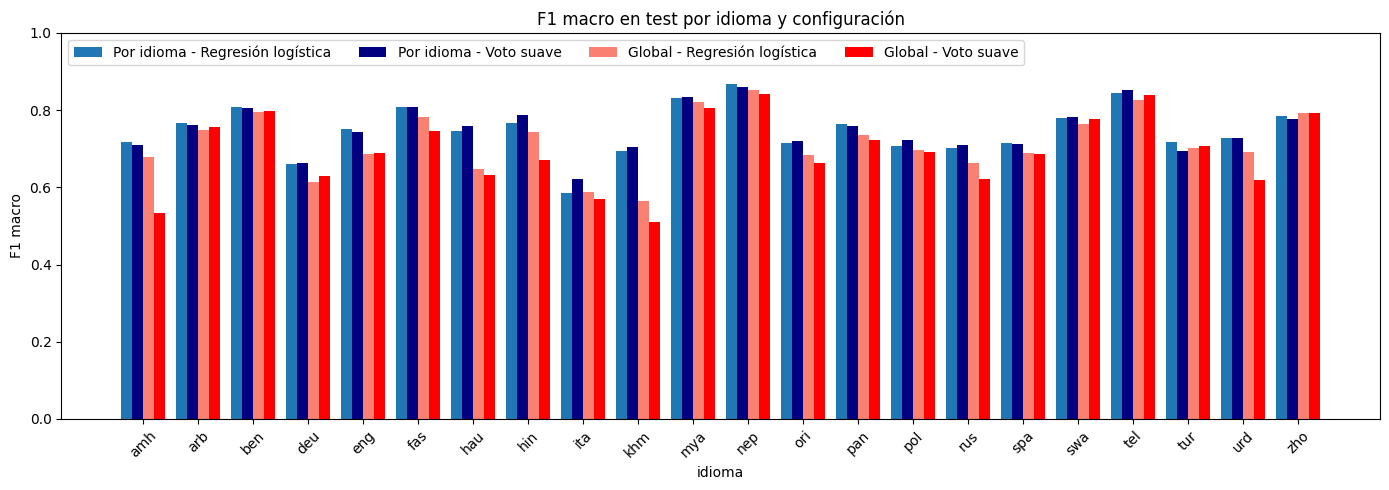

In [12]:
# F1 macro por idioma
display(f1_test.round(3))

x = np.arange(len(idiomas))
colores = {('Por idioma', 'Regresión logística'): 'tab:blue', ('Por idioma', 'Voto suave'): 'navy',
           ('Global', 'Regresión logística'): 'salmon', ('Global', 'Voto suave'): 'red'}

plt.figure(figsize = (14, 5))
for k, config in enumerate(predicciones):
    plt.bar(x + (k - 1.5) * 0.2, f1_test[config], width = 0.2, color = colores[config], label = ' - '.join(config))
plt.xticks(x, idiomas, rotation = 45)
plt.ylim(0, 1)
plt.xlabel('idioma')
plt.ylabel('F1 macro')
plt.title('F1 macro en test por idioma y configuración')
plt.legend(ncol = 4, loc = 'upper left')
plt.tight_layout()
plt.show()

La tabla y la gráfica muestran el F1 macro de cada configuración en cada idioma. Las barras azules (por idioma) quedan por encima de las rojas (globales) en casi todos los idiomas, y la diferencia es más visible en jemer, hausa, inglés y amhárico.

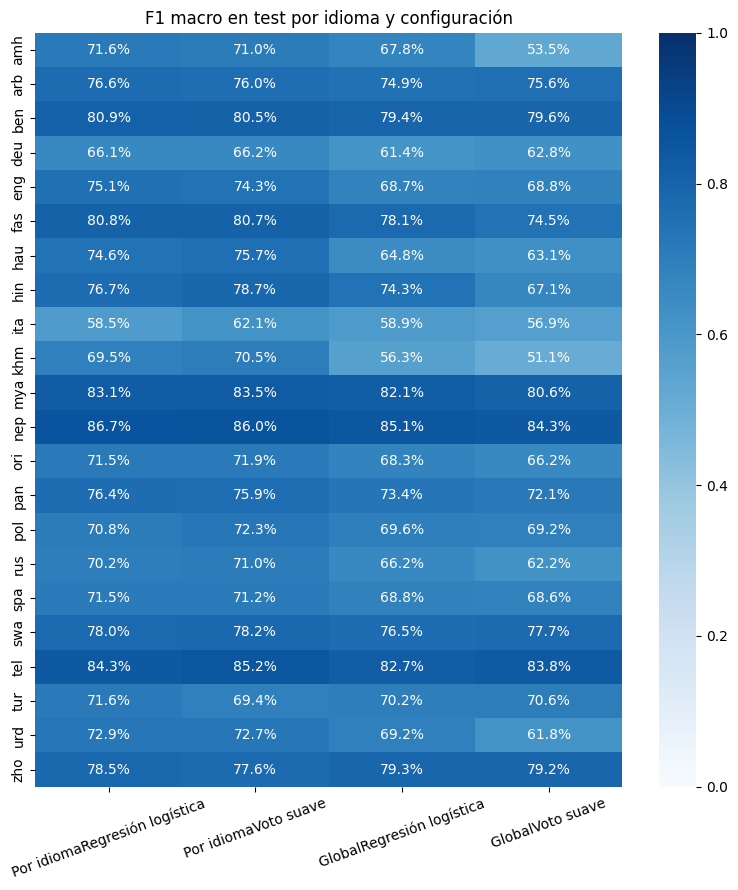

In [24]:
# F1 macro por idioma y configuración
f1_mapa = f1_test.copy()
f1_mapa.columns = [''.join(config) for config in f1_mapa.columns]

plt.figure(figsize = (8, 9))
sns.heatmap(f1_mapa, annot = True, fmt = '.1%', cmap = 'Blues', vmin = 0, vmax = 1)
plt.title('F1 macro en test por idioma y configuración')
plt.xticks(rotation = 20)
plt.tight_layout()
plt.show()

El mismo resultado se presenta como mapa de calor, que facilita ver qué idiomas son difíciles para todas las configuraciones. El italiano y el alemán tienen los valores más bajos en las cuatro columnas, mientras que el nepalí, el telugu y el birmano tienen los más altos.

In [15]:
# Diferencias pareadas por idioma
comparaciones = {
    'Voto suave vs. regresión logística (por idioma)': (('Por idioma', 'Voto suave'), ('Por idioma', 'Regresión logística')),
    'Voto suave vs. regresión logística (global)': (('Global', 'Voto suave'), ('Global', 'Regresión logística')),
    'Por idioma vs. global (regresión logística)': (('Por idioma', 'Regresión logística'), ('Global', 'Regresión logística')),
    'Por idioma vs. global (voto suave)': (('Por idioma', 'Voto suave'), ('Global', 'Voto suave'))
}
display(pd.DataFrame({nombre: {'diferencia media': (f1_test[a] - f1_test[b]).mean(),
                               'idiomas donde mejora': (f1_test[a] > f1_test[b]).sum(),
                               'p (Wilcoxon)': wilcoxon(f1_test[a], f1_test[b]).pvalue}
                      for nombre, (a, b) in comparaciones.items()}).T.round(4))

,diferencia media,idiomas donde mejora,p (Wilcoxon)
Voto suave vs. regresión logística (por idioma),0.0021,11.0,0.5661
Voto suave vs. regresión logística (global),-0.0212,7.0,0.0115
Por idioma vs. global (regresión logística),0.0317,20.0,0.0000
Por idioma vs. global (voto suave),0.0550,20.0,0.0000


Para saber si las diferencias son consistentes se comparan las configuraciones por pares, idioma por idioma. Para cada par se calcula la diferencia media de F1 macro, en cuántos idiomas mejora la primera configuración y el valor p de la prueba de Wilcoxon pareada, que no supone normalidad y funciona bien con solo 22 observaciones.

* **Entrenar por idioma es claramente mejor que un modelo global.** Con regresión logística, el metamodelo por idioma gana 3.2 puntos de F1 macro en promedio, y con el voto suave gana 5.5, y en ambos casos mejora en 20 de los 22 idiomas. Las mayores diferencias están en los idiomas con clases más desbalanceadas, como el jemer (91% polarizado) y el hausa (11%), ya que un modelo global tiene un solo intercepto y un solo umbral y no puede adaptarse a la proporción de clases de cada idioma. Las excepciones son el chino en ambos casos, el italiano con regresión logística y el turco con voto suave.
* **El F1 macro sobre todo `test` oculta esa diferencia.** Las cuatro configuraciones quedan alrededor de 0.78, debido a que al juntar todos los idiomas los errores de uno se compensan con los aciertos de otro. El promedio por idioma le da el mismo peso a cada idioma, que es lo que interesa en una tarea multilingüe, y es ahí donde se ve la ventaja del metamodelo.
* **En `test`, el voto suave por idioma no mejora de forma confiable a la regresión logística por idioma.** La diferencia media es de 0.2 puntos, mejora en 11 de los 22 idiomas y la prueba de Wilcoxon no la distingue de cero (p = 0.57). Ayuda bastante en italiano (+3.6), hindi (+2.0), polaco (+1.5), hausa (+1.1) y jemer (+1.0), pero empeora en turco (-2.2), chino (-0.9) e inglés (-0.8). La mejora de casi un punto que se vio en la selección no se sostuvo, probablemente por dos razones. Por un lado, se eligió la mejor de 16 configuraciones, lo que infla su resultado en validación. Por otro, en la selección la regresión logística tenía `C = 10` fijo, mientras que aquí cada idioma eligió su `C` (casi siempre entre 0.3 y 3, es decir, más regularizado), lo que deja menos errores para que el Random Forest corrija.
* **El voto global es peor que la regresión logística global** (-2.1 puntos). Usa un solo umbral (0.46) para todos los idiomas, y en idiomas muy desbalanceados como el amhárico, el jemer o el urdu ese umbral queda muy mal ubicado. Además, con 100 árboles y 762 mil variables el bosque global es más débil que los bosques por idioma.
* **En cuanto al costo**, el voto suave por idioma tarda unas 15 veces más en entrenarse que la regresión logística por idioma (3.7 contra 0.2 minutos).

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Guardado</span></div>

In [16]:
os.makedirs(ruta_predicciones, exist_ok = True)
nombres = {('Por idioma', 'Regresión logística'): 'idioma_lr', ('Por idioma', 'Voto suave'): 'idioma_voto',
           ('Global', 'Regresión logística'): 'global_lr', ('Global', 'Voto suave'): 'global_voto'}
salida = test[['id', 'idioma', 'polarization']].copy()
for config, pred in predicciones.items():
    salida[nombres[config]] = pred
salida.to_csv(os.path.join(ruta_predicciones, 'task1_test.csv'), index = False)
display(salida.head())

,id,idioma,polarization,idioma_lr,idioma_voto,global_lr,global_voto
0,amh_00019453da74933d5b35f6dfb52761f3,amh,0,1,1,1,1
1,amh_000c3060ec412c2570a560d8b298989b,amh,1,1,1,1,1
2,amh_0028bfcc62a5a47ab6fdaf37f166b301,amh,1,1,1,1,1
3,amh_002b8ea7f4ecb837e03827565dd12ba2,amh,1,0,1,1,1
4,amh_00306c304d57dbf71dd492129eb08557,amh,1,1,1,1,1


Se guardan las predicciones de las cuatro configuraciones sobre `test` en `data/predicciones/task1_test.csv`, junto con el `id`, el idioma y la etiqueta verdadera. Así se pueden analizar los errores sin volver a entrenar, y la subtarea 2 puede usar estas predicciones para la cascada.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">F1 macro por idioma de la configuración elegida</span></div>

In [18]:
# F1 de cada clase y F1 macro por idioma de la regresión logística por idioma
predichas = pd.read_csv(os.path.join(ruta_predicciones, 'task1_test.csv'))

filas = {}
for i, g in predichas.groupby('idioma'):
    f1 = f1_score(g['polarization'], g['idioma_lr'], average = None, zero_division = 0)
    filas[i] = {'no polarizado': f1[0], 'polarizado': f1[1], 'F1 macro': f1.mean()}
tabla_idioma = pd.DataFrame(filas).T
tabla_idioma.loc['Promedio'] = tabla_idioma.mean()

display(tabla_idioma.style.format('{:.1%}').background_gradient(cmap = 'Blues', vmin = 0, vmax = 1))

,no polarizado,polarizado,F1 macro
amh,58.4%,84.9%,71.6%
arb,78.7%,74.5%,76.6%
ben,84.6%,77.3%,80.9%
deu,66.0%,66.1%,66.1%
eng,80.6%,69.6%,75.1%
fas,72.1%,89.5%,80.8%
hau,93.6%,55.5%,74.6%
hin,61.1%,92.4%,76.7%
ita,64.6%,52.5%,58.5%
khm,45.3%,93.7%,69.5%


Esta tabla resume el resultado final de la subtarea 1 con la configuración recomendada, la regresión logística por idioma, que también es la que se usa para la cascada de la subtarea 2. Se calcula a partir de las predicciones guardadas en `data/predicciones/task1_test.csv`, así que no depende de los modelos en memoria.

El F1 macro de cada idioma sale de tres pasos.

1. Se comparan las predicciones con las etiquetas reales en todos los textos de `test` de ese idioma y se cuentan los verdaderos positivos ($VP$), los falsos positivos ($FP$) y los falsos negativos ($FN$), primero tomando como positiva la clase polarizada y después la no polarizada.
2. Con esos conteos se obtiene el F1 de cada clase, $F_1 = \frac{2\,VP}{2\,VP + FP + FN}$, que es la media armónica entre la precisión y la exhaustividad.
3. El F1 macro del idioma es el promedio simple de los dos F1, de modo que ambas clases pesan lo mismo sin importar cuántos textos tenga cada una.

La última fila es el promedio de los 22 idiomas, el mismo valor que aparece como F1 macro promedio por idioma de la regresión logística por idioma en la evaluación.

Leyendo la tabla por idioma se ve qué clase sostiene o hunde cada F1 macro.

* **Nepalí (0.867), telugu (0.843), birmano (0.831) y bengalí (0.809)** son los mejores, y en los cuatro las dos clases quedan por encima de 0.77, entonces el modelo distingue bien en ambos sentidos.
* **En los idiomas con muchos polarizados la clase débil es la no polarizada.** El jemer, con 91% de polarizados en `test`, tiene un F1 de 0.94 en la clase polarizada pero solo 0.45 en la no polarizada. Pasa lo mismo, aunque en menor medida, en hindi (0.92 contra 0.61), amhárico (0.85 contra 0.58) y urdu (0.82 contra 0.64). El persa sigue el mismo patrón (0.90 contra 0.72), pero su clase minoritaria es lo bastante buena para quedar entre los cinco mejores.
* **En los idiomas con pocos polarizados ocurre lo contrario.** El hausa, con solo 11% de polarizados, tiene 0.94 en la clase no polarizada y 0.56 en la polarizada, y el ruso (0.82 contra 0.59) y el oriya (0.83 contra 0.60) se comportan igual.
* **El italiano (0.585) y el alemán (0.661) son los peores, pero por otra razón.** Sus clases están casi balanceadas y las dos tienen un F1 bajo (entre 0.53 y 0.66), por lo que el problema no es el desbalance sino que los n-gramas de caracteres no alcanzan a separar bien los textos en esos idiomas. El español y el turco (0.715 y 0.716) están en una situación parecida, aunque menos marcada.

En general, el F1 macro de un idioma baja cuando su clase minoritaria es difícil de detectar, puesto que esa clase pesa lo mismo en el promedio aunque tenga muchos menos textos. El italiano es la excepción, ya que es difícil en ambas clases, y también resulta ser uno de los idiomas más débiles en la subtarea 2.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

* Se construyó un metamodelo, `ClasificadorPorIdioma`, que recibe textos de cualquiera de los 22 idiomas y envía cada uno al vectorizador y al modelo de su idioma, conservando el orden de las filas. Acepta como modelo base cualquier clasificador de `scikit-learn`, así que también sirve para la subtarea 2.
* Entrenar un modelo por idioma es la decisión que más importa, ya que supera al modelo global en 20 de los 22 idiomas, por 3 a 5 puntos de F1 macro en promedio, sobre todo en los idiomas con clases muy desbalanceadas.
* En la selección de modelos con validación cruzada, el voto suave de regresión logística y Random Forest con umbral ajustado fue el mejor ensamble, por encima del stacking y de las combinaciones con LinearSVC o Naive Bayes. El Random Forest por sí solo es el peor modelo, pero aporta diversidad al ensamble.
* En `test`, sin embargo, el voto suave por idioma (F1 macro medio de 0.750) queda prácticamente empatado con la regresión logística por idioma (0.748), cuesta 15 veces más entrenarlo y su ventaja no es estadísticamente significativa. Una regresión logística por idioma con `C` ajustado por validación cruzada es un modelo base igual de bueno y mucho más barato, y por eso es la configuración recomendada.
* El F1 macro varía mucho entre idiomas, desde 0.59 en italiano hasta 0.87 en nepalí. En los idiomas desbalanceados el error se concentra en la clase minoritaria, mientras que en italiano y alemán las dos clases son difíciles. Para mejorar la subtarea 1 parece más prometedor trabajar en estos idiomas o probar otra representación que seguir combinando modelos sobre los mismos n-gramas de caracteres.
* Las predicciones de las cuatro configuraciones sobre `test` quedaron en `data/predicciones/task1_test.csv`.